# King County Housing Market Analysis Using SQL

## Project Overview

This project analyzes 21,613 house sales in King County, Washington, from May 2014 to May 2015. The goal is to understand how housing prices vary based on location, number of bedrooms, living area, and time.

I used SQL with SQLite to explore the dataset, check data quality, and analyze housing prices. Python and Matplotlib were used to visualize the results.

## Tools Used

- **SQL (SQLite)** — Data exploration and analysis
- **Python (Pandas)** — Data loading and SQL query results
- **Matplotlib** — Data visualization
- **Google Colab** — Project development

## Dataset

- **Source:** King County House Sales Dataset (Kaggle)
- **Records:** 21,613
- **Features:** 21 columns
- **Time Period:** May 2014 – May 2015

In [4]:
import pandas as pd
import sqlite3

df = pd.read_csv('/kc_house_data.csv')

print(df.shape)
df.head()

(21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [5]:
conn = sqlite3.connect("housing_analysis.db")

df.to_sql(
    "housing_sales",
    conn,
    if_exists="replace",
    index=False
)

21613

In [6]:
query = "SELECT * FROM housing_sales LIMIT 5;"

pd.read_sql_query(query, conn)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [7]:
query = """
SELECT
    COUNT(*) AS total_sales,
    ROUND(AVG(price), 2) AS avg_price,
    MIN(price) AS min_price,
    MAX(price) AS max_price
FROM housing_sales;
"""

pd.read_sql_query(query, conn)

,total_sales,avg_price,min_price,max_price
0,21613,540088.14,75000.0,7700000.0


In [8]:
pd.read_sql_query("""
SELECT
    COUNT(*) - COUNT(price) AS missing_price,
    COUNT(*) - COUNT(bedrooms) AS missing_bedrooms,
    COUNT(*) - COUNT(bathrooms) AS missing_bathrooms,
    COUNT(*) - COUNT(sqft_living) AS missing_sqft,
    COUNT(*) - COUNT(zipcode) AS missing_zipcode
FROM housing_sales;
""", conn)

,missing_price,missing_bedrooms,missing_bathrooms,missing_sqft,missing_zipcode
0,0,0,0,0,0


In [9]:
pd.read_sql_query("""
SELECT
    id,
    date,
    COUNT(*) AS duplicate_count
FROM housing_sales
GROUP BY id, date
HAVING COUNT(*) > 1;
""", conn)

,id,date,duplicate_count


In [10]:
pd.read_sql_query("""
SELECT *
FROM housing_sales
WHERE price <= 0
   OR sqft_living <= 0
   OR bedrooms < 0
   OR bathrooms < 0;
""", conn)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


In [11]:
pd.read_sql_query("""
SELECT
    id,
    price,
    bedrooms,
    bathrooms,
    sqft_living,
    zipcode
FROM housing_sales
ORDER BY price DESC
LIMIT 10;
""", conn)

,id,price,bedrooms,bathrooms,sqft_living,zipcode
0,6762700020,7700000.0,6,8.00,12050,98102
1,9808700762,7062500.0,5,4.50,10040,98004
2,9208900037,6885000.0,6,7.75,9890,98039
3,2470100110,5570000.0,5,5.75,9200,98039
4,8907500070,5350000.0,5,5.00,8000,98004
5,7558700030,5300000.0,6,6.00,7390,98040
6,1247600105,5110800.0,5,5.25,8010,98033
7,1924059029,4668000.0,5,6.75,9640,98040
8,7738500731,4500000.0,5,5.50,6640,98155
9,3835500195,4489000.0,4,3.00,6430,98004


In [12]:
pd.read_sql_query("""
SELECT
    id,
    price,
    bedrooms,
    bathrooms,
    sqft_living
FROM housing_sales
ORDER BY bedrooms DESC
LIMIT 10;
""", conn)

,id,price,bedrooms,bathrooms,sqft_living
0,2402100895,640000.0,33,1.75,1620
1,1773100755,520000.0,11,3.00,3000
2,627300145,1148000.0,10,5.25,4590
3,5566100170,650000.0,10,2.00,3610
4,8812401450,660000.0,10,3.00,2920
5,1997200215,599999.0,9,4.50,3830
6,2902200015,700000.0,9,3.00,3680
7,9822700190,1280000.0,9,4.50,3650
8,424049043,450000.0,9,7.50,4050
9,8823900290,1400000.0,9,4.00,4620


In [13]:
pd.read_sql_query("""
SELECT
    bedrooms,
    COUNT(*) AS house_count
FROM housing_sales
GROUP BY bedrooms
ORDER BY bedrooms DESC;
""", conn)

,bedrooms,house_count
0,33,1
1,11,1
2,10,3
3,9,6
4,8,13
5,7,38
6,6,272
7,5,1601
8,4,6882
9,3,9824


## Data Cleaning Summary

I checked the dataset for missing values, duplicate records,
invalid values, and potential outliers.

### Data Quality Checks

- Missing Values: No NULL values were found in the five
  columns checked.
- Duplicates: No duplicate ID and date combinations were found.
- Invalid Values: No invalid prices or negative room counts
  were found.
- Outliers: One house had 33 bedrooms and 1,620 sqft of
  living space, which may be a data entry error.

### Data Handling

I kept the original dataset without deleting any records.

For the bedroom analysis, I focused on houses with 1–6
bedrooms to compare more common housing types.

In [14]:
pd.read_sql_query("""
SELECT
    bedrooms,
    COUNT(*) AS house_count,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
WHERE bedrooms BETWEEN 1 AND 6
GROUP BY bedrooms
ORDER BY bedrooms;
""", conn)

,bedrooms,house_count,avg_price
0,1,199,317642.88
1,2,2760,401372.68
2,3,9824,466232.08
3,4,6882,635419.50
4,5,1601,786599.83
5,6,272,825520.64


In [15]:
pd.read_sql_query("""
SELECT
    zipcode,
    COUNT(*) AS house_count,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
GROUP BY zipcode
ORDER BY avg_price DESC
LIMIT 10;
""", conn)

,zipcode,house_count,avg_price
0,98039,50,2160606.60
1,98004,317,1355927.08
2,98040,282,1194230.02
3,98112,269,1095499.34
4,98102,105,901258.27
5,98109,109,879623.62
6,98105,229,862825.23
7,98006,498,859684.78
8,98119,184,849448.02
9,98005,168,810164.88


In [16]:
pd.read_sql_query("""
SELECT
    CASE
        WHEN sqft_living < 1000 THEN 'Under 1000'
        WHEN sqft_living < 2000 THEN '1000-1999'
        WHEN sqft_living < 3000 THEN '2000-2999'
        WHEN sqft_living < 4000 THEN '3000-3999'
        ELSE '4000+'
    END AS size_group,
    COUNT(*) AS house_count,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
GROUP BY size_group
ORDER BY MIN(sqft_living);
""", conn)

,size_group,house_count,avg_price
0,Under 1000,1421,297241.08
1,1000-1999,10188,397559.45
2,2000-2999,6882,576993.97
3,3000-3999,2332,870012.35
4,4000+,790,1519580.38


In [17]:
pd.read_sql_query("""
SELECT
    SUBSTR(date, 1, 4) || '-' || SUBSTR(date, 5, 2) AS month,
    COUNT(*) AS house_count,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
GROUP BY month
ORDER BY month;
""", conn)

,month,house_count,avg_price
0,2014-05,1768,548080.28
1,2014-06,2180,558002.20
2,2014-07,2211,544788.76
3,2014-08,1940,536445.28
4,2014-09,1774,529253.82
5,2014-10,1878,539026.97
6,2014-11,1411,521961.01
7,2014-12,1471,524461.87
8,2015-01,978,525870.89
9,2015-02,1250,507851.37


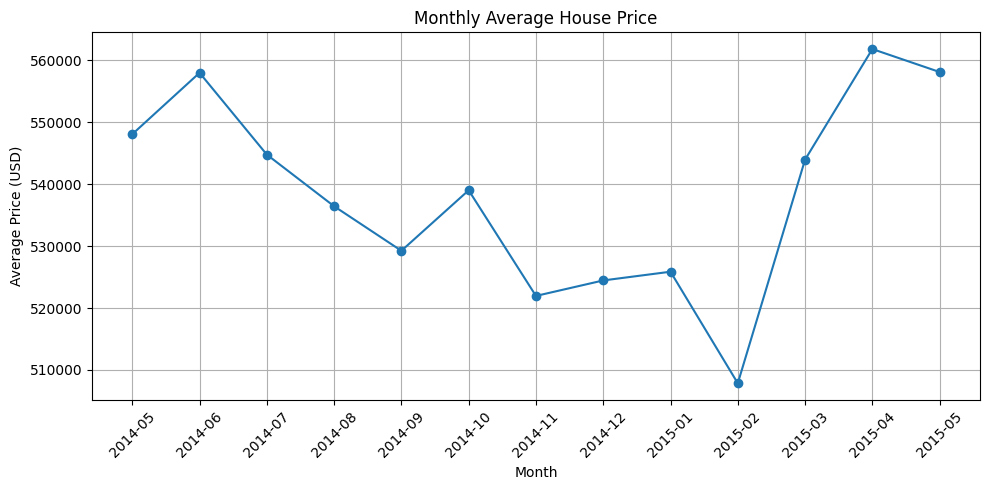

In [18]:
import matplotlib.pyplot as plt

monthly_df = pd.read_sql_query("""
SELECT
    SUBSTR(date, 1, 4) || '-' || SUBSTR(date, 5, 2) AS month,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
GROUP BY month
ORDER BY month;
""", conn)

plt.figure(figsize=(10, 5))
plt.plot(monthly_df["month"], monthly_df["avg_price"], marker="o")

plt.title("Monthly Average House Price")
plt.xlabel("Month")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

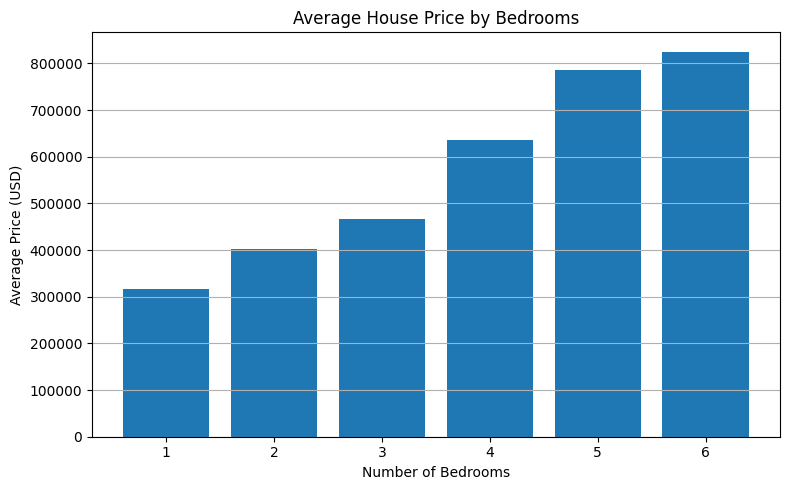

In [19]:
bedroom_df = pd.read_sql_query("""
SELECT
    bedrooms,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
WHERE bedrooms BETWEEN 1 AND 6
GROUP BY bedrooms
ORDER BY bedrooms;
""", conn)

plt.figure(figsize=(8, 5))
plt.bar(bedroom_df["bedrooms"], bedroom_df["avg_price"])

plt.title("Average House Price by Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average Price (USD)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

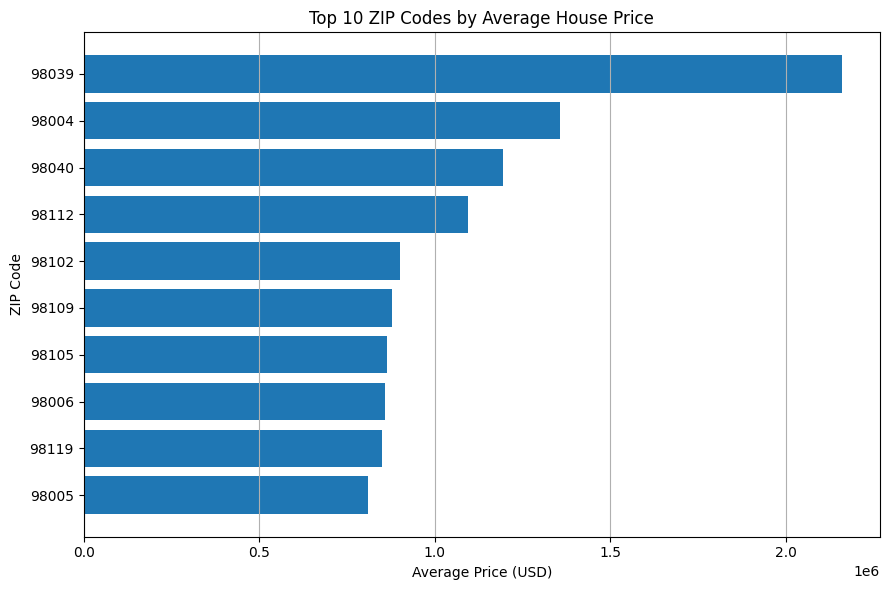

In [20]:
zip_df = pd.read_sql_query("""
SELECT
    zipcode,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
GROUP BY zipcode
ORDER BY avg_price DESC
LIMIT 10;
""", conn)

plt.figure(figsize=(9, 6))
plt.barh(zip_df["zipcode"].astype(str), zip_df["avg_price"])

plt.title("Top 10 ZIP Codes by Average House Price")
plt.xlabel("Average Price (USD)")
plt.ylabel("ZIP Code")
plt.gca().invert_yaxis()
plt.grid(axis="x")
plt.tight_layout()
plt.show()

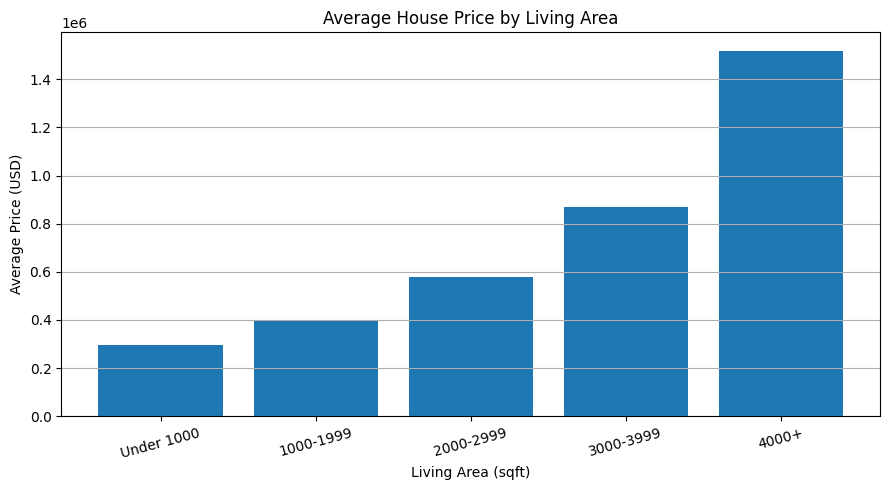

In [21]:
size_df = pd.read_sql_query("""
SELECT
    CASE
        WHEN sqft_living < 1000 THEN 'Under 1000'
        WHEN sqft_living < 2000 THEN '1000-1999'
        WHEN sqft_living < 3000 THEN '2000-2999'
        WHEN sqft_living < 4000 THEN '3000-3999'
        ELSE '4000+'
    END AS size_group,
    ROUND(AVG(price), 2) AS avg_price
FROM housing_sales
GROUP BY size_group
ORDER BY MIN(sqft_living);
""", conn)

plt.figure(figsize=(9, 5))
plt.bar(size_df["size_group"], size_df["avg_price"])

plt.title("Average House Price by Living Area")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [22]:
pd.read_sql_query("""
WITH house_prices AS (
    SELECT
        zipcode,
        price / sqft_living AS price_per_sqft
    FROM housing_sales
    WHERE sqft_living > 0
)

SELECT
    zipcode,
    COUNT(*) AS house_count,
    ROUND(AVG(price_per_sqft), 2) AS avg_price_per_sqft
FROM house_prices
GROUP BY zipcode
HAVING COUNT(*) >= 30
ORDER BY avg_price_per_sqft DESC
LIMIT 10;
""", conn)

,zipcode,house_count,avg_price_per_sqft
0,98039,50,568.08
1,98004,317,475.44
2,98112,269,438.64
3,98109,109,433.40
4,98119,184,432.26
5,98102,105,423.17
6,98105,229,405.15
7,98040,282,387.29
8,98107,266,382.95
9,98199,317,376.55


In [24]:
mom_df = pd.read_sql_query("""
WITH monthly_prices AS (
    SELECT
        SUBSTR(date, 1, 4) || '-' || SUBSTR(date, 5, 2) AS month,
        AVG(price) AS avg_price
    FROM housing_sales
    GROUP BY month
),
monthly_changes AS (
    SELECT
        month,
        avg_price,
        LAG(avg_price) OVER (ORDER BY month) AS prev_price
    FROM monthly_prices
)

SELECT
    month,
    ROUND(avg_price, 2) AS avg_price,
    ROUND(prev_price, 2) AS prev_price,
    ROUND((avg_price - prev_price) / prev_price * 100, 2) AS mom_change_pct
FROM monthly_changes
ORDER BY month;
""", conn)
mom_df

,month,avg_price,prev_price,mom_change_pct
0,2014-05,548080.28,NaN,NaN
1,2014-06,558002.20,548080.28,1.81
2,2014-07,544788.76,558002.20,-2.37
3,2014-08,536445.28,544788.76,-1.53
4,2014-09,529253.82,536445.28,-1.34
5,2014-10,539026.97,529253.82,1.85
6,2014-11,521961.01,539026.97,-3.17
7,2014-12,524461.87,521961.01,0.48
8,2015-01,525870.89,524461.87,0.27
9,2015-02,507851.37,525870.89,-3.43


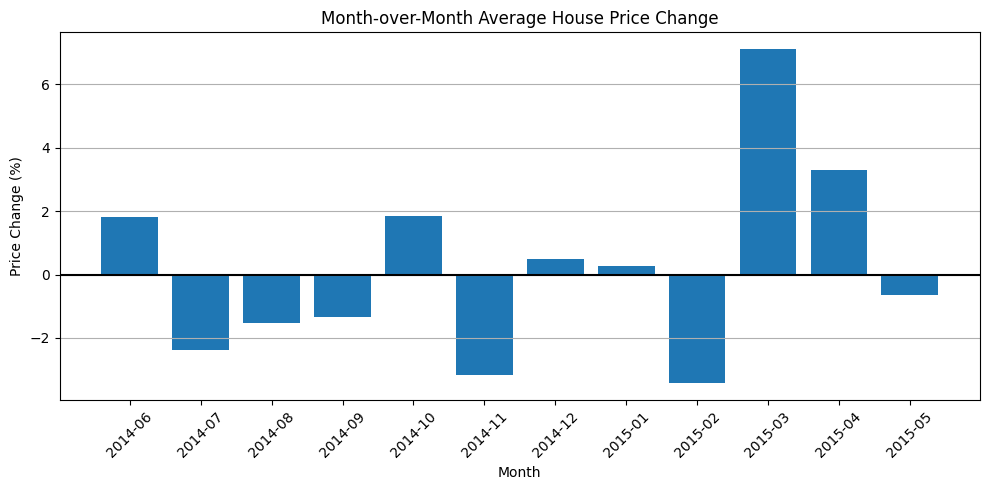

In [25]:
chart_df = mom_df.dropna(subset=["mom_change_pct"])

plt.figure(figsize=(10, 5))
plt.bar(chart_df["month"], chart_df["mom_change_pct"])

plt.title("Month-over-Month Average House Price Change")
plt.xlabel("Month")
plt.ylabel("Price Change (%)")
plt.xticks(rotation=45)
plt.axhline(0, color="black")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

## Key Findings

### 1. Bedrooms and House Prices

Average house prices generally increased with the number
of bedrooms. Houses with 3 bedrooms were the most common,
with 9,824 sales.

### 2. Location and House Prices

ZIP Code 98039 had the highest average house price at
approximately $2.16 million, followed by 98004 and 98040.

### 3. Living Area and House Prices

Larger houses generally had higher average prices.
Houses under 1,000 sqft averaged about $297K, while houses
over 4,000 sqft averaged about $1.52M.

### 4. Monthly Price Trends

Monthly average prices fluctuated between May 2014 and
May 2015. April 2015 had the highest average price, while
February 2015 had the lowest.

## Conclusion

This project used SQL to explore housing sales data and
analyze price differences based on location, bedrooms,
living area, and time.

The results show that house size and location are
associated with housing prices.

Through this project, I practiced SQL queries including
SELECT, WHERE, GROUP BY, HAVING, ORDER BY, and
aggregate functions.

I also used Python and Matplotlib to visualize the results.